# HOM simulation with a noise model - Gray code encoding

SparsePauliOp(['IXIX', 'IXXI', 'IXXZ', 'IXZX', 'IYIY', 'IYYI', 'IYYZ', 'IYZY', 'XIIX', 'XIXI', 'XIXZ', 'XIZX', 'XZIX', 'XZXI', 'XZXZ', 'XZZX', 'YIIY', 'YIYI', 'YIYZ', 'YIZY', 'YZIY', 'YZYI', 'YZYZ', 'YZZY', 'ZXIX', 'ZXXI', 'ZXXZ', 'ZXZX', 'ZYIY', 'ZYYI', 'ZYYZ', 'ZYZY'],
              coeffs=[ 0.09817477+0.j,  0.13884009+0.j, -0.13884009+0.j,  0.09817477+0.j,
  0.09817477+0.j,  0.13884009+0.j, -0.13884009+0.j,  0.09817477+0.j,
  0.13884009+0.j,  0.19634954+0.j, -0.19634954+0.j,  0.13884009+0.j,
 -0.13884009+0.j, -0.19634954+0.j,  0.19634954+0.j, -0.13884009+0.j,
  0.13884009+0.j,  0.19634954+0.j, -0.19634954+0.j,  0.13884009+0.j,
 -0.13884009+0.j, -0.19634954+0.j,  0.19634954+0.j, -0.13884009+0.j,
  0.09817477+0.j,  0.13884009+0.j, -0.13884009+0.j,  0.09817477+0.j,
  0.09817477+0.j,  0.13884009+0.j, -0.13884009+0.j,  0.09817477+0.j])
{'1110': 192, '1010': 145, '0111': 327, '1000': 222, '0110': 402, '1001': 581, '0011': 3006, '0001': 339, '1100': 2530, '0100': 375, '1011': 247, '0101': 

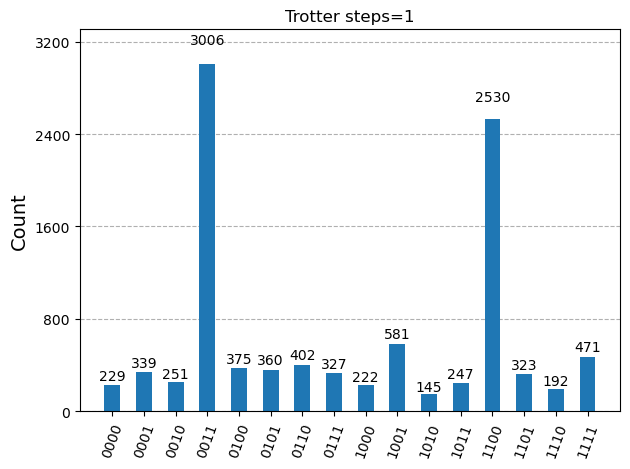

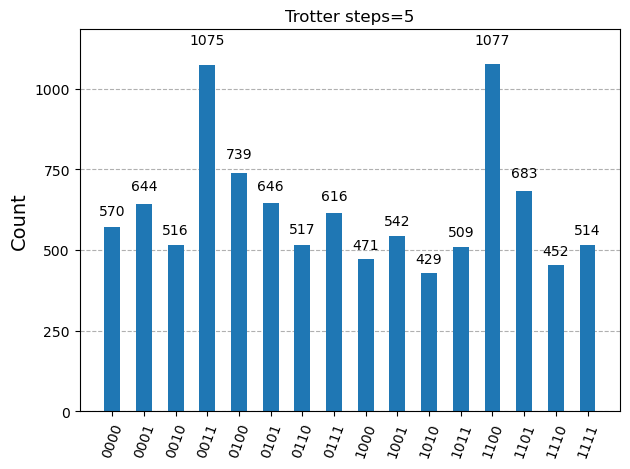

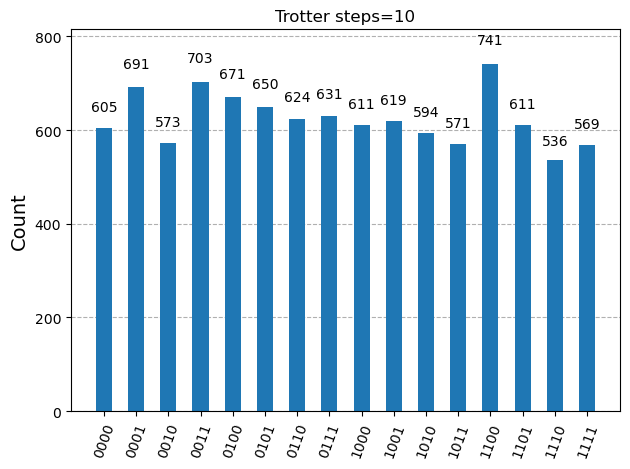

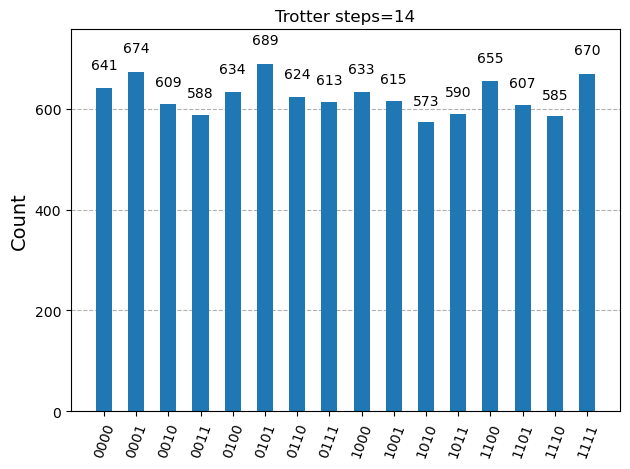

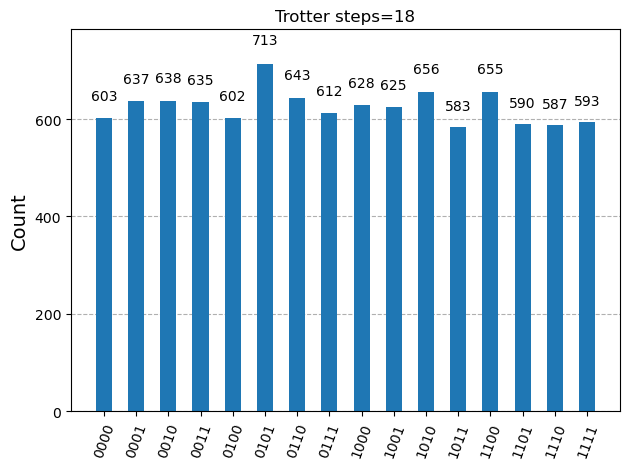

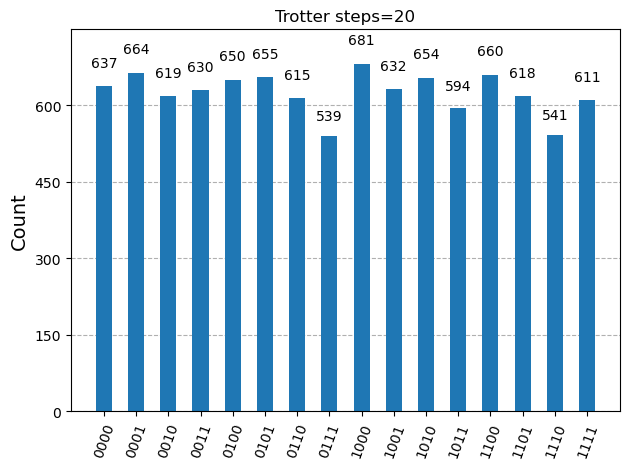

In [5]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Operator, Pauli
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import Operator
from qiskit.visualization import plot_histogram
from qiskit.synthesis import LieTrotter
from qiskit_aer import AerSimulator
from IPython.display import display, Math
import matplotlib.pyplot as plt
%matplotlib inline
from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, \
    amplitude_damping_error, phase_damping_error, ReadoutError

X=Operator(Pauli("X")).data
Y=Operator(Pauli("Y")).data
Z=Operator(Pauli("Z")).data
I=np.eye(2,dtype=complex)

P_0=0.5*(I+Z)
P_1=0.5*(I-Z)

Q_0=0.5*(X+1j*Y)
Q_1=0.5*(X-1j*Y)

dag= np.kron(P_0,Q_1) + np.sqrt(2)* np.kron(Q_1,P_1)
nor= np.kron(P_0,Q_0) + np.sqrt(2)* np.kron(Q_0,P_1)

I4=np.eye(4,dtype=complex)

bdag= np.kron(I4,dag)
b=np.kron(I4,nor)

adag= np.kron(dag,I4)
a=np.kron(nor,I4)

H=np.pi/4*(bdag@a + b@adag)

H_P= SparsePauliOp.from_operator(Operator(H))
H_P=H_P.simplify()
print(H_P)


def BScircuit(trotter_steps):
    qc=QuantumCircuit(4,4)
    qc.x(0)
    qc.x(2)
    evolution= PauliEvolutionGate(H_P,time=1,synthesis=LieTrotter(reps=trotter_steps),label="U_B")
    qc.append(evolution,[0,1,2,3])
    qc.measure(range(4),range(4))
    return qc
    
single_qubit_gate_duration = 10e-9
two_qubit_gate_duration    = 200e-9

relaxation_time   = 256e-6
dephasing_time    = 654e-6

measurement_flip_prob = 0.0123
two_qubit_depol_rate  = 0.00655

noise_model = NoiseModel()

gamma_1q  = 1 - np.exp(-single_qubit_gate_duration / relaxation_time)
lambda_1q = 1 - np.exp(-single_qubit_gate_duration / dephasing_time)


confusion = [
    [1 - measurement_flip_prob, measurement_flip_prob],
    [measurement_flip_prob,     1 - measurement_flip_prob],
]
noise_model.add_all_qubit_readout_error(ReadoutError(confusion))

thermal_2q = (
    amplitude_damping_error(gamma_2q)
    .tensor(amplitude_damping_error(gamma_2q))
    .compose(
        phase_damping_error(lambda_2q)
        .tensor(phase_damping_error(lambda_2q))
    )
)
noise_model.add_all_qubit_quantum_error(
    depolarizing_error(two_qubit_depol_rate, 2).compose(thermal_2q), ["cx"]
)


single_qubit_channel = (
    amplitude_damping_error(gamma_1q)
    .compose(phase_damping_error(lambda_1q))
)
noise_model.add_all_qubit_quantum_error(single_qubit_channel, ["h"])

backend = AerSimulator(noise_model=noise_model)

trotter_list=[1,5,10,14,18,20]


for n in trotter_list:
    compiled_circuit=transpile(BScircuit(trotter_steps=n), backend)
    job = backend.run(compiled_circuit, shots=10000)
    
    result = job.result()
    counts = result.get_counts()
    print(counts)     
    plot_histogram(counts, title=f"Trotter steps={n}")